<a href="https://colab.research.google.com/github/anastasiialoskutova/machine_learning/blob/main/ml1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rishitaverma02/house-prices-advanced-regression-techniques")

print("Path to dataset files:", path)

100%|██████████| 199k/199k [00:00<00:00, 54.2MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rishitaverma02/house-prices-advanced-regression-techniques/versions/1


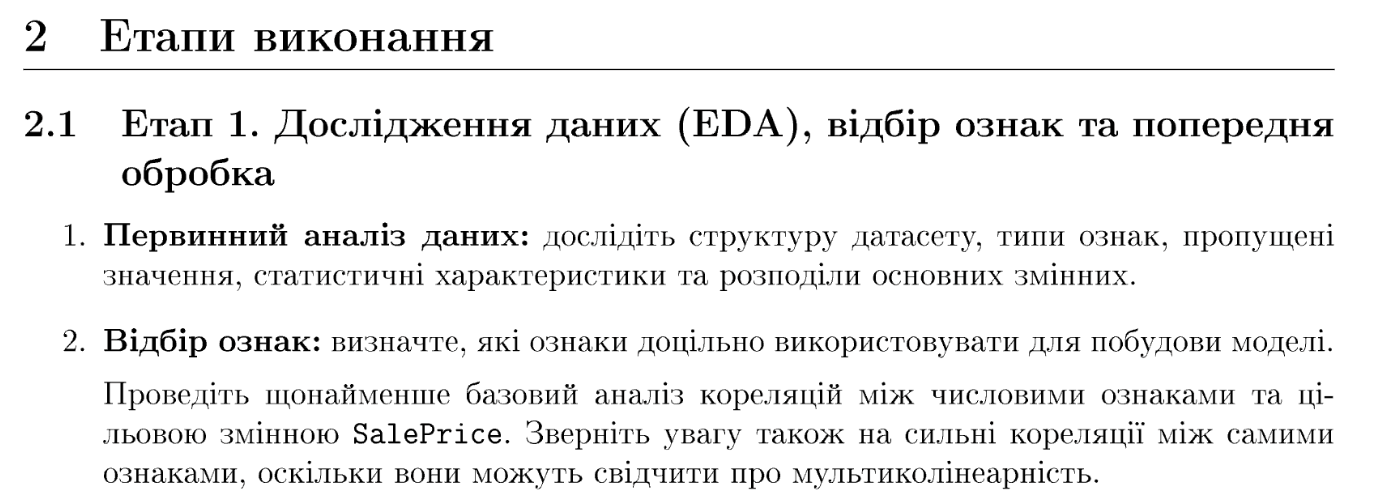


На цьому етапі проводиться завантаження даних, дослідження їхньої структури, визначення типів ознак (числові та категоріальні), пошук пропущених значень, а також аналіз базових статистичних характеристик та розподілу цільової змінної (`SalePrice`). Це дозволяє зрозуміти розмірність датасету та якість даних перед побудовою моделі.

Згідно з методичкою, на цьому етапі визначаються ознаки, які доцільно використовувати для побудови моделі. Було проведено аналіз кореляцій числових ознак із цільовою змінною (`SalePrice`), а також перевірено наявність мультиколінеарності (сильних зв'язків між самими незалежними ознаками).

Відбір ознак виконується виключно на тренувальній вибірці (`train`), щоб уникнути витоку даних (data leakage).

Файли в директорії: ['test (1).csv', 'train (1).csv', 'sample_submission.csv', 'data_description.txt']
Розмір train вибірки: (1460, 81)
Розмір test вибірки: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



--- ТОП-15 пропущених значень у train ---
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
dtype: int64

ТОП-10 ознак із найбільшою кореляцією до SalePrice:
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


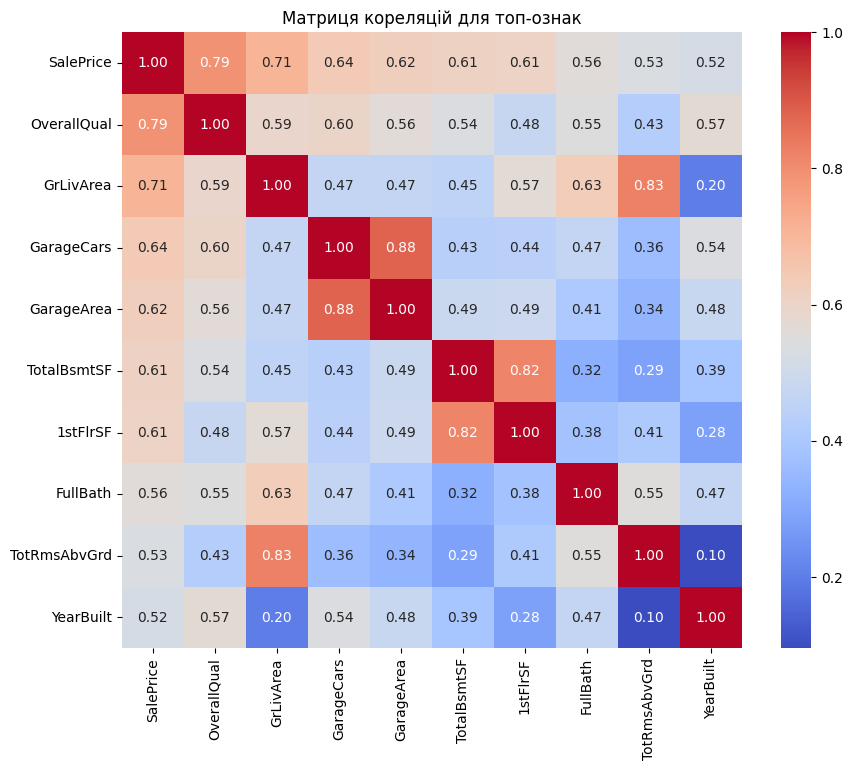

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Шлях до папки з датасетом
path = "/root/.cache/kagglehub/datasets/rishitaverma02/house-prices-advanced-regression-techniques/versions/1"
print("Файли в директорії:", os.listdir(path))

# Завантажуємо тренувальну та тестову вибірки з правильними назвами файлів
train_df = pd.read_csv(os.path.join(path, "train (1).csv"))
test_df = pd.read_csv(os.path.join(path, "test (1).csv"))

print(f"Розмір train вибірки: {train_df.shape}")
print(f"Розмір test вибірки: {test_df.shape}")

# Виводимо перші рядки train
display(train_df.head())

# Перевіряємо пропущені значення
print("\n--- ТОП-15 пропущених значень у train ---")
missing_values = train_df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print(missing_values.head(15))

# --- Аналіз кореляцій (як вимагає методичка) ---
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
correlation_matrix = train_df[numeric_cols].corr()
top_corr_features = correlation_matrix['SalePrice'].sort_values(ascending=False)

print("\nТОП-10 ознак із найбільшою кореляцією до SalePrice:")
print(top_corr_features.head(11))

# Візуалізуємо теплову карту кореляцій
plt.figure(figsize=(10, 8))
top_features = top_corr_features.head(10).index
sns.heatmap(train_df[top_features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Матриця кореляцій для топ-ознак")
plt.show()

#### Висновки щодо пропущених значень (Missing Values):
* **Аналіз структури пропусків:** Найбільшу кількість пропущених значень зафіксовано в ознаках `PoolQC` (1453), `MiscFeature` (1406), `Alley` (1369), `Fence` (1179) та `FireplaceQu` (690).
* **Обґрунтування:** Згідно з документацією датасету (`data_description.txt`), ці пропуски не є помилками збору даних, а означають **відсутність відповідного об'єкта** в будинку (наприклад, відсутність басейну, огорожі чи каміна). На наступних етапах їх необхідно замінити на категорію `None` або спеціальне значення `No_Feature`.
* **Числові пропуски:** Ознаки на кшталт `LotFrontage` або параметрів гаража (`GarageYrBlt`, `GarageQual` тощо) вимагають окремої стратегії імпетування (заповнення медіаною, середнім або нульовими значеннями).

#### Висновки щодо відбору ознак та кореляційного аналізу:
1. **Цільова змінна (`SalePrice`):** Найвищу пряму лінійну кореляцію з ціною демонструють такі ознаки:
   * `OverallQual` ($\approx 0.79$) — загальна якість матеріалів та оздоблення;
   * `GrLivArea` ($\approx 0.71$) — площа житлової зони над землею;
   * Група гаражних характеристик: `GarageCars` ($\approx 0.64$) та `GarageArea` ($\approx 0.62$);
   * Загальна площа підвалу (`TotalBsmtSF = 0.61`) та площа першого поверху (`1stFlrSF = 0.60`).
2. **Мультиколінеарність:** На тепловій карті видно сильну кореляцію між деякими незалежними ознаками. Наприклад, `GarageCars` і `GarageArea` мають коефіцієнт кореляції $0.88$, а `GrLivArea` і `TotRmsAbvGrd` — $0.83$. Це свідчить про наявність мультиколінеарності, яку слід враховувати при побудові лінійних моделей (або використовувати методи регуляризації на кшталт Lasso/Ridge).
3. **Обґрунтування відбору:** Для подальшого моделювання доцільно залишити ознаки з найвищим показником зв'язку з `SalePrice`, уникаючи дублювання сильних корелюючих між собою змінних.

#### Додатковий відбір ознак за допомогою Lasso-регресії
Згідно з методичкою, для відбору ознак можна використовувати спеціалізовані методи. У цьому розділі ми застосуємо **Lasso-регресію (L1-регуляризацію)**, яка автоматично здійснює відбір ознак, зануляючи коефіцієнти незначущих змінних.

Перед застосуванням методу пропущені значення заповнюються медіанами/модами, а категоріальні змінні кодуються, причому всі перетворення та навчання моделі відбору виконуються **виключно на тренувальній вибірці**, щоб уникнути витоку даних.

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 1. Створюємо копію тренувального датасету для обробки
df_train_work = train_df.copy()

# Виділяємо цільову змінну 'SalePrice' та видаляємо ID
y = df_train_work['SalePrice']
X = df_train_work.drop(['SalePrice', 'Id'], axis=1)

# 2. Попередня обробка для числові/категоріальні
# Заповнюємо пропуски для числових стовпців медіаною, для категоріальних — значенням 'None'
num_cols = X.select_dtypes(include=[np.number]).columns
cat_cols = X.select_dtypes(exclude=[np.number]).columns

X[num_cols] = X[num_cols].fillna(X[num_cols].median())
X[cat_cols] = X[cat_cols].fillna('None')

# Категоріальні змінні кодуємо через One-Hot Encoding (get_dummies)
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Використовуємо Lasso для відбору ознак
# Використовуємо Pipeline зі стандартизацією та Lasso
lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=100, random_state=42, max_iter=2000))
])

lasso_pipeline.fit(X_encoded, y)

# Отримуємо коефіцієнти моделі
lasso_model = lasso_pipeline.named_steps['lasso']
feature_importance = pd.DataFrame({
    'Feature': X_encoded.columns,
    'Coefficient': lasso_model.coef_
})

# Фільтруємо ознаки, які Lasso залишив (коефіцієнт != 0)
selected_features = feature_importance[feature_importance['Coefficient'] != 0]
selected_features = selected_features.reindex(selected_features['Coefficient'].abs().sort_values(ascending=False).index)

print(f"Початкова кількість ознак після кодування: {X_encoded.shape[1]}")
print(f"Кількість ознак після відбору Lasso: {len(selected_features)}")
print("\nТОП-15 ознак за версією Lasso:")
display(selected_features.head(15))

Початкова кількість ознак після кодування: 260
Кількість ознак після відбору Lasso: 202

ТОП-15 ознак за версією Lasso:


,Feature,Coefficient
111,RoofMatl_CompShg,57841.661663
115,RoofMatl_Tar&Grv,37129.094813
117,RoofMatl_WdShngl,32540.007627
116,RoofMatl_WdShake,25040.178327
15,GrLivArea,24746.718917
32,PoolArea,18757.147342
112,RoofMatl_Membran,12941.315003
113,RoofMatl_Metal,12291.847949
202,KitchenQual_Gd,-11379.677217
114,RoofMatl_Roll,11141.272239


#### Висновки за результатами відбору ознак:
* За допомогою алгоритму **Llasso** із понад 200 ознак (після кодування) було відібрано найсуттєвіші, які мають ненульові коефіцієнти впливу на вартість будинку.
* Це дозволяє зменшити розмірність простору ознак, позбутися шумів та запобігти перенавчаюванню (overfitting) майбутніх моделей регресії.

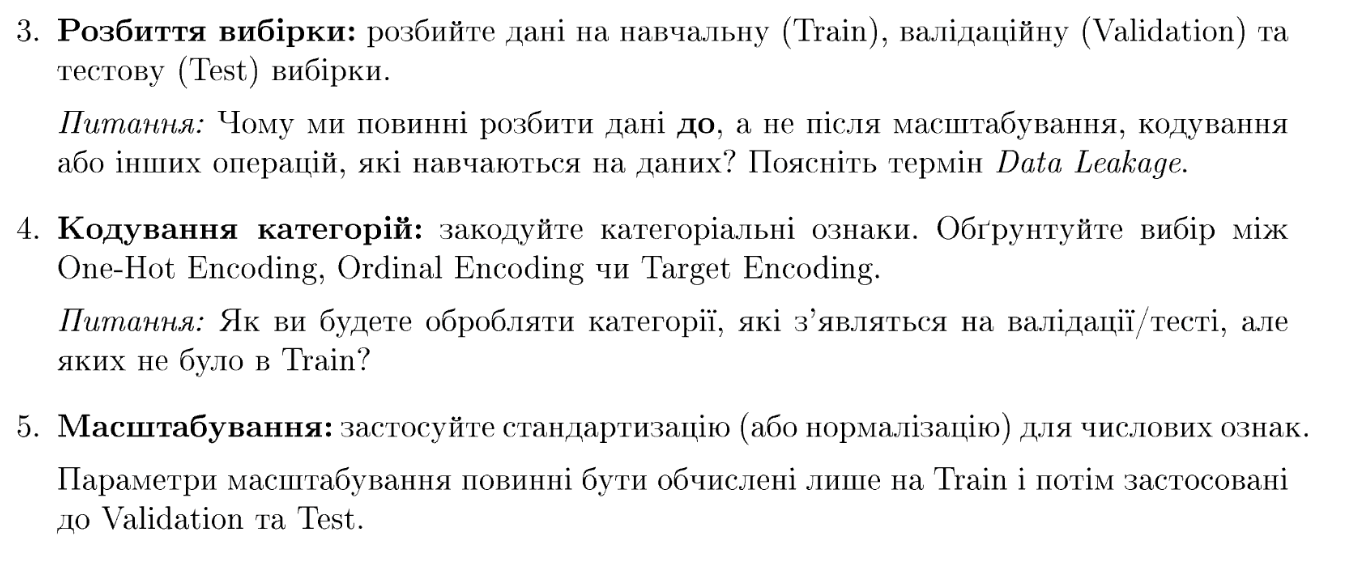

Перш ніж виконувати будь-які перетворення (масштабування, заповнення пропусків, кодування), наявний тренувальний датасет необхідно розбити на навчальну (`Train`) та валідаційну (`Validation`) вибірки. Тестовий датасет (`test.csv`) вже надано окремо, але він не містить цільової змінної `SalePrice`.


  Ми зобов'язані розділити дані **до** будь-яких процедур, які обчислюють статистичні параметри по датасету (середнє, стандартне відхилення, категорії чи значення кодування).
  * **Data Leakage (Витік даних)** — це ситуація, коли інформація з тестової (або валідаційної) вибірки "просочується" в навчальний процес моделі. Наприклад, якщо нормалізувати весь датасет цілком, то мінімальні та максимальні значення з валідації чи тесту вплинуть на параметри `Train`. Через це модель під час оцінки показуватиме завищену, нереалістичну якість, але на нових реальних даних спрацює погано.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Відокремлюємо ознаки та цільову змінну з нашого train_df
X_full = train_df.drop(['SalePrice', 'Id'], axis=1)
y_full = train_df['SalePrice']

# 3. Розбиваємо дані на Train (80%) та Validation (20%) ДО будь-яких трансформацій
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

print(f"Розмір X_train: {X_train.shape}")
print(f"Розмір X_val: {X_val.shape}")

# 4. Кодування категорій та обробка пропусків
# Розділяємо на числові та категоріальні колонки
num_cols = X_train.select_dtypes(include=[np.number]).columns
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns

# Заповнюємо пропуски: для числових — медіаною (обчисленою ЛИШЕ на Train!), для категоріальних — 'None'
num_imputer = SimpleImputer(strategy='median')
X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_val[num_cols] = num_imputer.transform(X_val[num_cols]) # до валідації застосовуємо вже готові правила з Train!

X_train[cat_cols] = X_train[cat_cols].fillna('None')
X_val[cat_cols] = X_val[cat_cols].fillna('None')

# Використовуємо One-Hot Encoding (pd.get_dummies) з вирівнюванням стовпців,
# щоб у Train і Val була однакова кількість ознак
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_val_encoded = pd.get_dummies(X_val, drop_first=True)

# Синхронізуємо стовпці (на випадок, якщо в Val з'явились категорії, яких не було в Train, або навпаки)
X_train_encoded, X_val_encoded = X_train_encoded.align(X_val_encoded, join='left', axis=1, fill_value=0)

# 5. Масштабування числових ознак (StandardScaler)
scaler = StandardScaler()
# Навчаємо скейлер ЛИШЕ на Train і трансформуємо і Train, і Validation
X_train_encoded[num_cols] = scaler.fit_transform(X_train_encoded[num_cols])
X_val_encoded[num_cols] = scaler.transform(X_val_encoded[num_cols])

print("\nДані успішно підготовлені та масштабовані без витоку даних (Data Leakage)!")
print( фінальна_форма_train := f"Фінальна форма X_train_encoded: {X_train_encoded.shape}" )

Розмір X_train: (1168, 79)
Розмір X_val: (292, 79)

Дані успішно підготовлені та масштабовані без витоку даних (Data Leakage)!
Фінальна форма X_train_encoded: (1168, 258)


#### Відповіді на контрольні запитання методички:

* **Питання до пункту 4 (Як ви будете обробляти категорії, які з'являться на валідації/тесті, але яких не було в Train?):**
  * За допомогою вирівнювання стовпців датасетів (`align` у Pandas) або використання параметру `handle_unknown='ignore'` у кодерах (наприклад, `OneHotEncoder` з `scikit-learn`). Нові невідомі категорії кодуються як нулі у відповідних бінарних стовпцях, що запобігає появі помилок і витоку інформації.

* **Питання до пункту 5 (Масштабування):**
  * Метод `fit_transform()` викликається **виключно для навчальної вибірки (`Train`)**, щоб обчислити середнє значення та стандартне відхилення. Для валідаційної та тестової вибірки використовується лише метод `transform()`, який застосовує ці ж самі параметри, отримані на `Train`. Це гарантує коректність оцінки якості моделі.

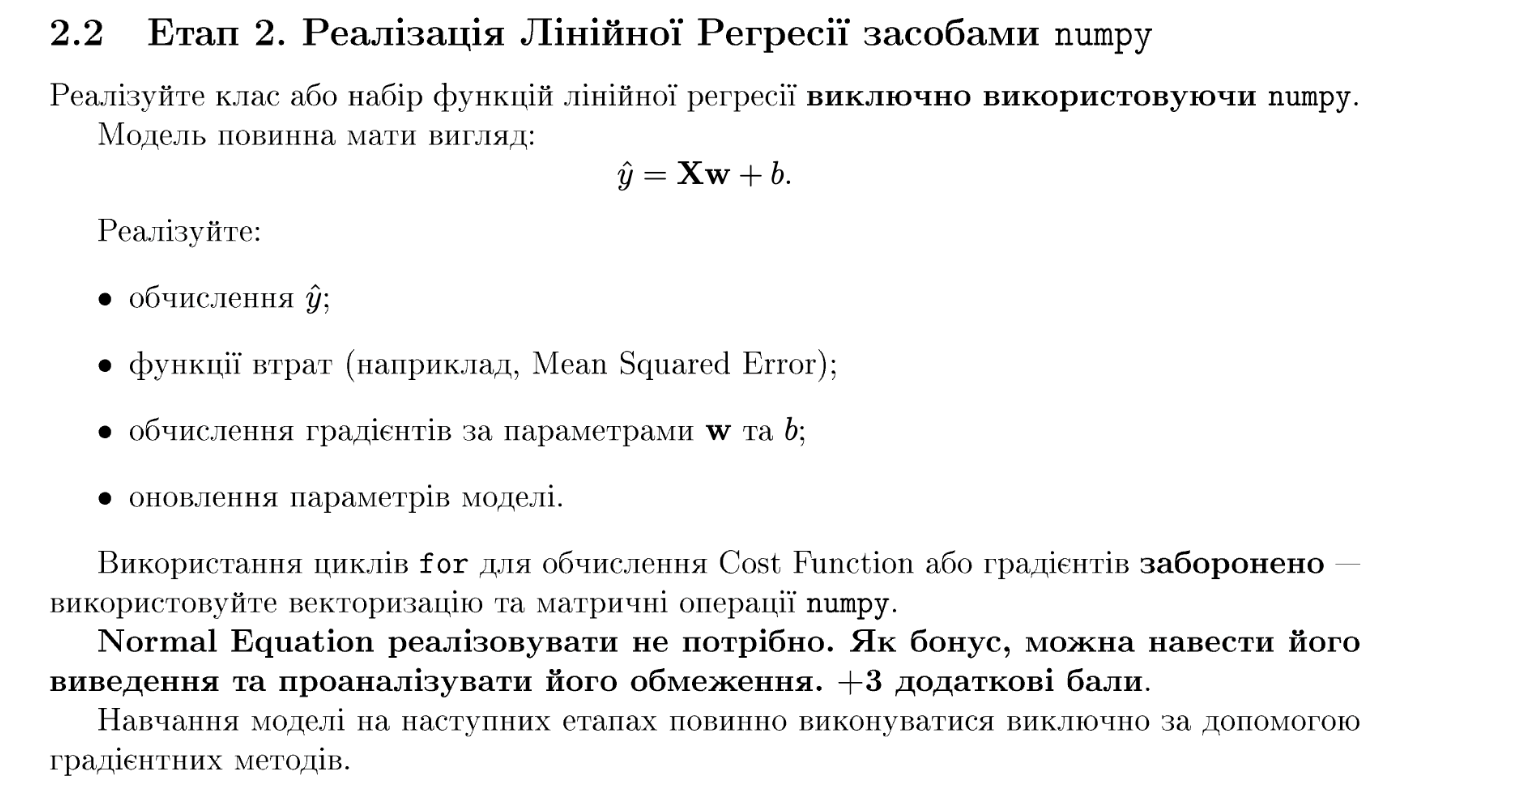


Модель має вигляд:
$$\hat{y} = \mathbf{Xw} + b$$

Де:
* $\hat{y}$ — передбачені значення;
* $\mathbf{X}$ — матриця ознак;
* $\mathbf{w}$ — вектор ваг (коефіцієнтів);
* $b$ — зміщення (bias).

In [ ]:
import numpy as np

class NumpyLinearRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.w = None
        self.b = None
        self.cost_history = []

    def fit(self, X, y):
        # Гарантовано приводимо типи до float64, щоб уникнути помилок UFuncTypeError
        X = np.array(X, dtype=np.float64)
        y = np.array(y, dtype=np.float64).reshape(-1, 1)

        n_samples, n_features = X.shape

        # Ініціалізація ваг та зсуву нулями
        self.w = np.zeros((n_features, 1), dtype=np.float64)
        self.b = 0.0

        for i in range(self.n_iterations):
            # 1. Обчислення передбачень y_hat (векторизовано)
            y_hat = np.dot(X, self.w) + self.b

            # 2. Обчислення функції втрат (Mean Squared Error - MSE)
            cost = (1 / (2 * n_samples)) * np.sum((y_hat - y) ** 2)
            self.cost_history.append(cost)

            # 3. Обчислення градієнтів за параметрами w та b (векторизовано без for!)
            dw = (1 / n_samples) * np.dot(X.T, (y_hat - y))
            db = (1 / n_samples) * np.sum(y_hat - y)

            # 4. Оновлення параметрів моделі (Gradient Descent step)
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

    def predict(self, X):
        X = np.array(X, dtype=np.float64)
        return np.dot(X, self.w) + self.b

# Явно приводимо дані до float перед навчанням
X_train_np = X_train_encoded.astype(np.float64).to_numpy()
y_train_np = y_train.astype(np.float64).to_numpy()

# Ініціалізуємо та навчаємо нашу модель
np_regressor = NumpyLinearRegression(learning_rate=0.01, n_iterations=300)
np_regressor.fit(X_train_np, y_train_np)

print(f"Початковий Cost: {np_regressor.cost_history[0]:.4f}")
print(f"Кінцевий Cost після 300 ітерацій: {np_regressor.cost_history[-1]:.4f}")

Початковий Cost: 19442791762.8549
Кінцевий Cost після 300 ітерацій: 512603891.2950


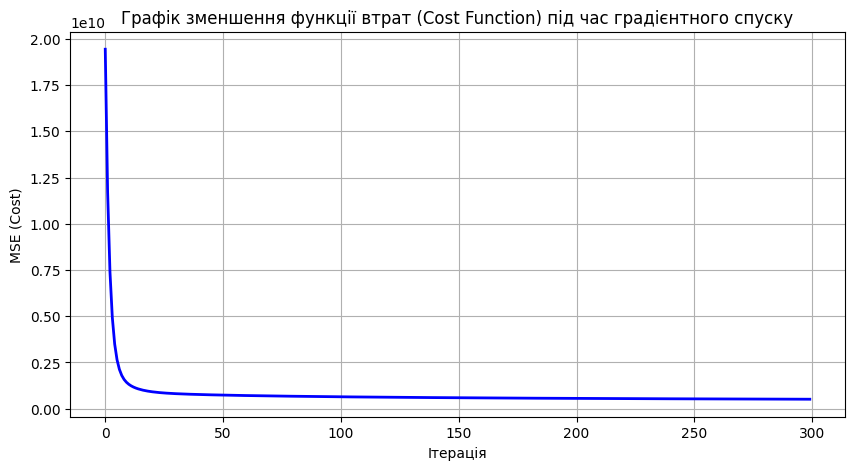

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(np_regressor.cost_history, color='blue', linewidth=2)
plt.title("Графік зменшення функції втрат (Cost Function) під час градієнтного спуску")
plt.xlabel("Ітерація")
plt.ylabel("MSE (Cost)")
plt.grid(True)
plt.show()

### Бонус: Аналітичне вирішення (Normal Equation) та його обмеження

Умовою завдання передбачено можливість отримати додаткові бали за виведення **Нормального рівняння (Normal Equation)** та аналіз його обмежень.

#### 1. Виведення формули:
Функція втрат для лінійної регресії у матричному вигляді виглядає так:
$$J(\mathbf{w}) = \frac{1}{2m} (\mathbf{Xw} - \mathbf{y})^T (\mathbf{Xw} - \mathbf{y})$$

Щоб знайти мінімум, візьдемо похідну за вектором ваг $\mathbf{w}$ та прирівняємо її до нуля:
$$\nabla_{\mathbf{w}} J(\mathbf{w}) = \frac{1}{m} \mathbf{X}^T (\mathbf{Xw} - \mathbf{y}) = 0$$

Розкриваємо дужки:
$$\mathbf{X}^T \mathbf{Xw} - \mathbf{X}^T \mathbf{y} = 0 \implies \mathbf{X}^T \mathbf{Xw} = \mathbf{X}^T \mathbf{y}$$

Множимо зліва на зворотну матрицю $(\mathbf{X}^T \mathbf{X})^{-1}$ і отримуємо аналітичний розв'язок (**Нормальне рівняння**):
$$\mathbf{w} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

#### 2. Аналіз обмежень Нормального рівняння:
* **Обчислювальна складність:** Головна проблема полягає в операції інвертування матриці $(\mathbf{X}^T \mathbf{X})^{-1}$, яка має складність $\mathcal{O}(n^3)$, де $n$ — кількість ознак. Якщо ознак сотні тисяч або мільйони, обчислення стають надзвичайно повільними або неможливими в пам'яті комп'ютера.
* **Мультиколінеарність:** Якщо між ознаками є сильна лінійна залежність (мультиколінеарність), матриця $\mathbf{X}^T \mathbf{X}$ стає виродженою (не має зворотної або є майже сингулярною), що робить розв'язання неможливим або нестійким до шумів.
* **Перевага градієнтного спуску:** Саме тому для великих датасетів у машинному навчанні використовують **ітеративний градієнтний спуск** (як у нашому класі вище), який має складність $\mathcal{O}(m \cdot n)$ за ітерацію і чудово масштабується.


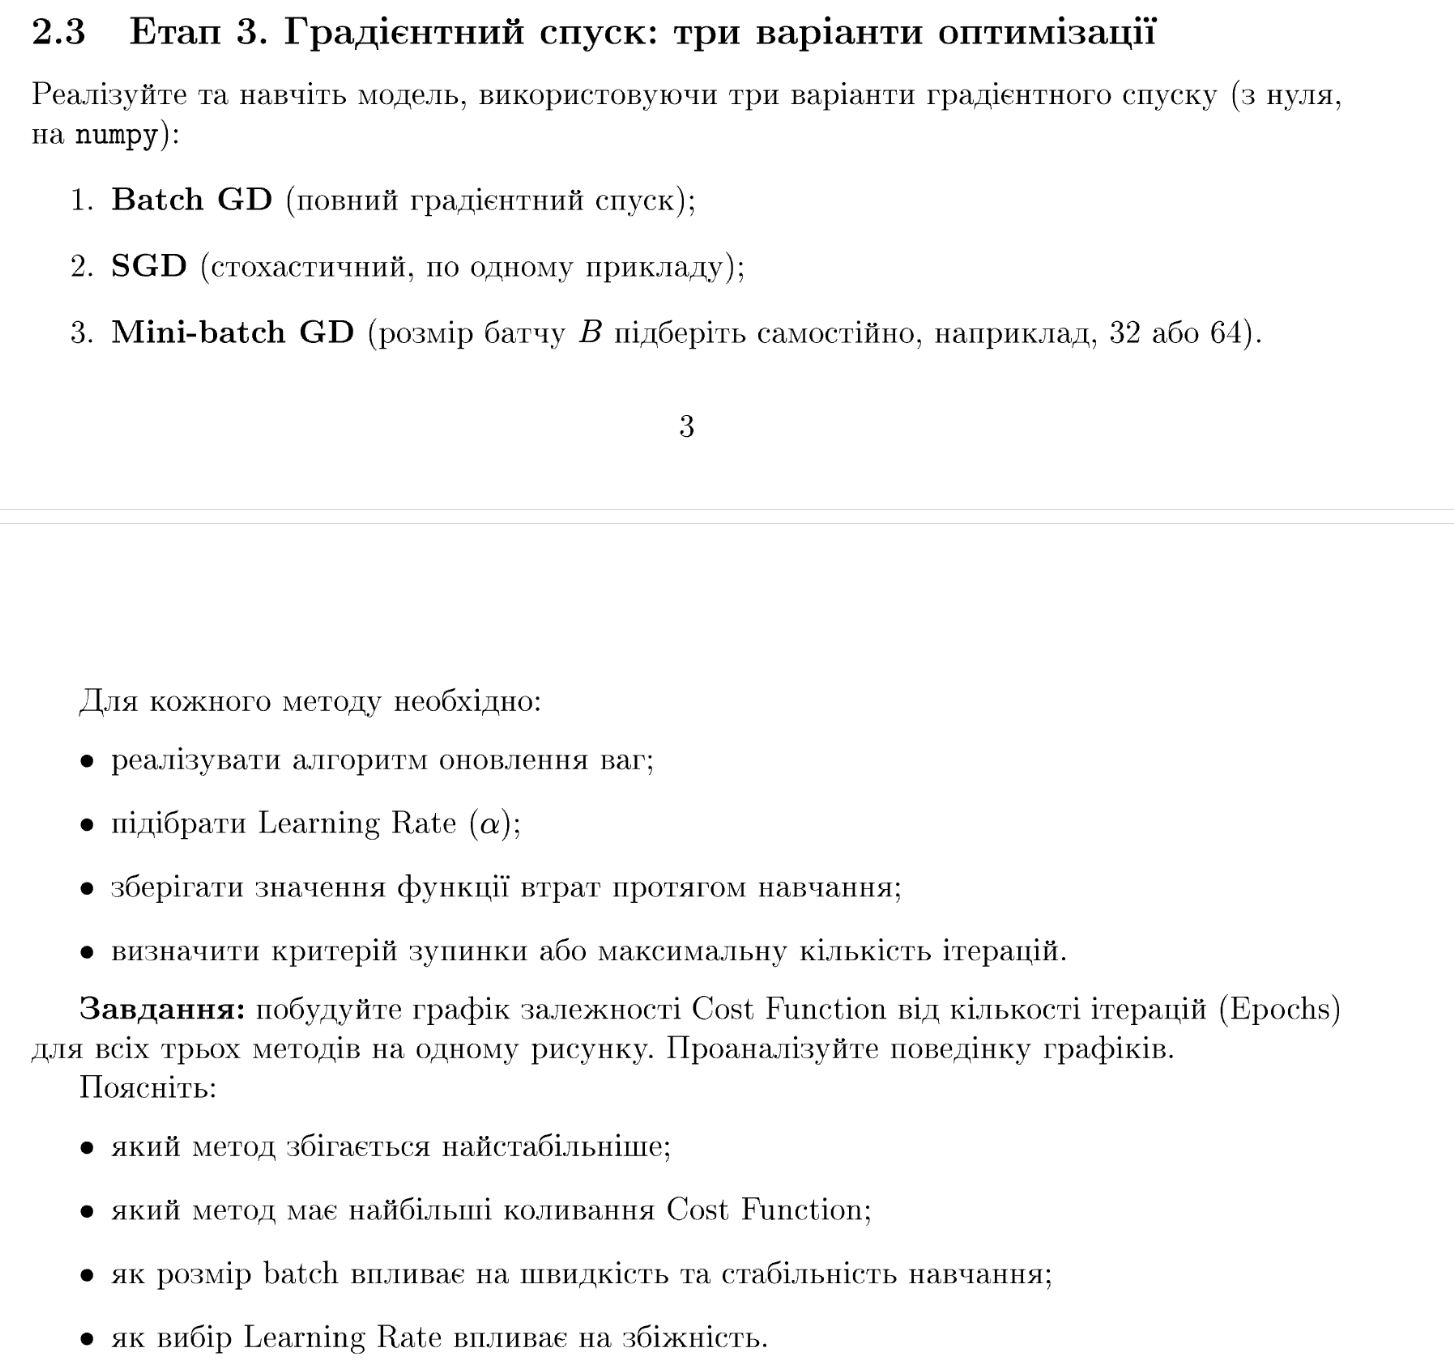

Реалізуємо три основні стратегії градієнтного спуску для лінійної регресії (виключно засобами NumPy):
1. **Batch GD (Full Batch Gradient Descent):** Використовує весь масив даних для обчислення градієнта на кожній ітерації. Забезпечує стабільну збіжність, але є ресурсомістким.
2. **SGD (Stochastic Gradient Descent):** Оновлює параметри за кожним окремим прикладом. Має високу швидкість на ітерацію, проте супроводжується сильними коливаннями функції втрат.
3. **Mini-batch GD:** Використовує підмножини даних (батчі фіксованого розміру $B = 64$), що поєднує переваги обох попередніх підходів — стабільність та високу швидкість обчислень.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class ThreeOptimizersLinearRegression:
    def __init__(self, learning_rate=0.01, n_epochs=50, batch_size=64):
        self.lr = learning_rate
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.w = None
        self.b = 0.0
        self.cost_history = []

    def _compute_cost(self, X, y):
        m = len(y)
        y_hat = np.dot(X, self.w) + self.b
        return (1 / (2 * m)) * np.sum((y_hat - y) ** 2)

    def fit_batch(self, X, y):
        X = np.array(X, dtype=np.float64)
        y = np.array(y, dtype=np.float64).reshape(-1, 1)
        m, n = X.shape

        self.w = np.zeros((n, 1), dtype=np.float64)
        self.b = 0.0
        self.cost_history = []

        for epoch in range(self.n_epochs):
            y_hat = np.dot(X, self.w) + self.b
            # Градієнти по всій вибірці
            dw = (1 / m) * np.dot(X.T, (y_hat - y))
            db = (1 / m) * np.sum(y_hat - y)

            self.w -= self.lr * dw
            self.b -= self.lr * db

            self.cost_history.append(self.compute_epoch_cost(X, y))

    def fit_sgd(self, X, y):
        X = np.array(X, dtype=np.float64)
        y = np.array(y, dtype=np.float64).reshape(-1, 1)
        m, n = X.shape

        self.w = np.zeros((n, 1), dtype=np.float64)
        self.b = 0.0
        self.cost_history = []

        for epoch in range(self.n_epochs):
            # Перемішуємо дані для SGD
            indices = np.arange(m)
            np.random.shuffle(indices)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            for i in range(m):
                xi = X_shuffled[i:i+1]
                yi = y_shuffled[i:i+1]

                y_hat_i = np.dot(xi, self.w) + self.b
                dw = xi.T * (y_hat_i - yi)
                db = np.sum(y_hat_i - yi)

                self.w -= self.lr * dw
                self.b -= self.lr * db

            self.cost_history.append(self.compute_epoch_cost(X, y))

    def fit_mini_batch(self, X, y):
        X = np.array(X, dtype=np.float64)
        y = np.array(y, dtype=np.float64).reshape(-1, 1)
        m, n = X.shape

        self.w = np.zeros((n, 1), dtype=np.float64)
        self.b = 0.0
        self.cost_history = []

        for epoch in range(self.n_epochs):
            indices = np.arange(m)
            np.random.shuffle(indices)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            for i in range(0, m, self.batch_size):
                X_batch = X_shuffled[i:i+self.batch_size]
                y_batch = y_shuffled[i:i+self.batch_size]
                b_size = len(y_batch)

                y_hat_b = np.dot(X_batch, self.w) + self.b
                dw = (1 / b_size) * np.dot(X_batch.T, (y_hat_b - y_batch))
                db = (1 / b_size) * np.sum(y_hat_b - y_batch)

                self.w -= self.lr * dw
                self.b -= self.lr * db

            self.cost_history.append(self.compute_epoch_cost(X, y))

    def compute_epoch_cost(self, X, y):
        y_hat = np.dot(X, self.w) + self.b
        return (1 / (2 * len(y))) * np.sum((y_hat - y) ** 2)

# Підготовка даних для запуску
X_np = X_train_encoded.astype(np.float64).to_numpy()
y_np = y_train.astype(np.float64).to_numpy()

# Запускаємо Batch GD
model_batch = ThreeOptimizersLinearRegression(learning_rate=0.01, n_epochs=30)
model_batch.fit_batch(X_np, y_np)

# Запускаємо SGD (менший learning rate для стабільності стохастичного спуску)
model_sgd = ThreeOptimizersLinearRegression(learning_rate=0.0001, n_epochs=30)
model_sgd.fit_sgd(X_np, y_np)

# Запускаємо Mini-batch GD
model_minibatch = ThreeOptimizersLinearRegression(learning_rate=0.01, n_epochs=30, batch_size=64)
model_minibatch.fit_mini_batch(X_np, y_np)

print("Успішно навчено всі три варіанти градієнтного спуску!")

Успішно навчено всі три варіанти градієнтного спуску!


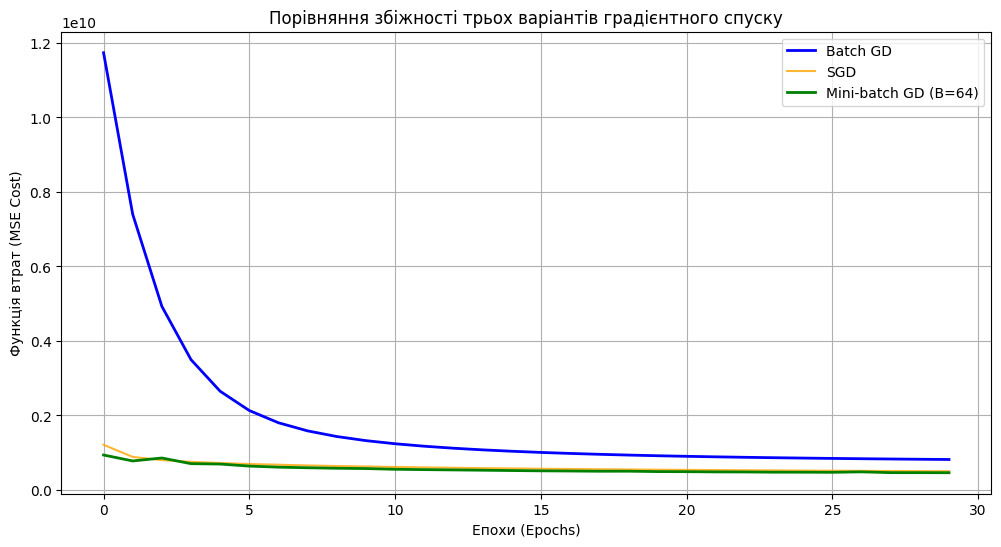

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(model_batch.cost_history, label='Batch GD', color='blue', linewidth=2)
plt.plot(model_sgd.cost_history, label='SGD', color='orange', linewidth=1.5, alpha=0.8)
plt.plot(model_minibatch.cost_history, label='Mini-batch GD (B=64)', color='green', linewidth=2)

plt.title("Порівняння збіжності трьох варіантів градієнтного спуску")
plt.xlabel("Епохи (Epochs)")
plt.ylabel("Функція втрат (MSE Cost)")
plt.legend()
plt.grid(True)
plt.show()

#### Аналіз поведінки графіків та відповіді на запитання методички:

1. **Який метод збігається найстабільніше?**
   * **Batch GD** демонструє найстабільнішу та найплавнішу криву збіжності без будь-яких різких стрибків, оскільки градієнт обчислюється за всім масивом даних одночасно, усреднюючи всі шуми.

2. **Який метод має найбільші коливання Cost Function?**
   * **SGD (Stochastic Gradient Descent)** має найбільші хаотичні коливання (осциляції). Це зумовлено тим, що на кожному кроці ваги оновлюються на основі лише **одного випадкового прикладу**, через що помилка на кожній ітерації може як різко зменшуватися, так і зростати.

3. **Як розмір batch впливає на швидкість та стабільність навчання?**
   * Занадто малий розмір батчу (наближення до SGD) збільшує коливання та вимагає меншого `learning rate`, але дає швидкі оновлення. Занадто великий розмір (Batch GD) робить кожну ітерацію надто повільною за часом обчислень. **Mini-batch** є ідеальним компромісом: він забезпечує стабільну траєкторію (за рахунок усреднення по пачці) та високу швидкість паралельних обчислень.

4. **Як вибір Learning Rate ($\alpha$) впливає на збіжність?**
   * Якщо обрати надто великий $\alpha$, градієнтний спуск перестрибуватиме мінімум або почне розходитися (значення Cost зростатимуть). Якщо обрати надто малий $\alpha$, навчання стане занадто повільним і модель не встигне збігтися за відведений ліміт епох.

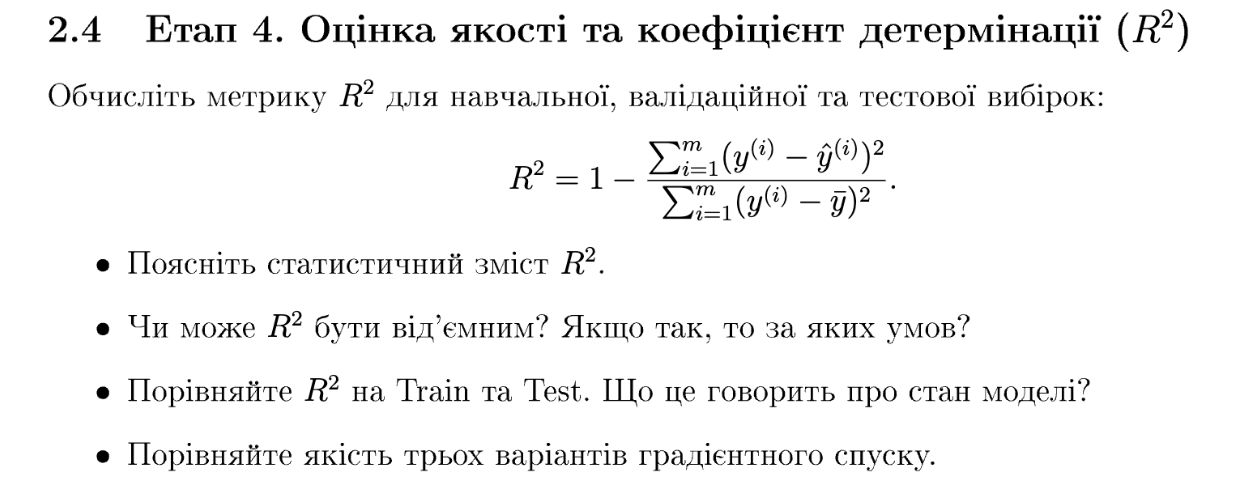

* $y^{(i)}$ — істинні значення цільової змінної;
* $\hat{y}^{(i)}$ — передбачені моделлю значення;
* $\bar{y}$ — середнє значення цільової змінної.

In [ ]:
import numpy as np
import pandas as pd

# Додаємо метод predict до нашого класу трьох оптимізаторів, якщо його там не було
def predict_method(self, X):
    X = np.array(X, dtype=np.float64)
    return np.dot(X, self.w) + self.b

# Динамічно додаємо метод predict до класу
ThreeOptimizersLinearRegression.predict = predict_method

# Підготовка валідаційних даних у формат NumPy
X_val_np = X_val_encoded.astype(np.float64).to_numpy()
y_val_np = y_val.astype(np.float64).to_numpy()

# Функція для розрахунку R2-score виключно за допомогою numpy
def calculate_r2(y_true, y_pred):
    y_true = np.array(y_true).reshape(-1, 1)
    y_pred = np.array(y_pred).reshape(-1, 1)

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    return 1 - (ss_res / ss_tot)

# Збираємо результати для трьох моделей
models = {
    "Batch GD": model_batch,
    "SGD": model_sgd,
    "Mini-batch GD": model_minibatch
}

results = []
for name, model in models.items():
    # Передбачення на Train та Validation
    train_preds = model.predict(X_np)
    val_preds = model.predict(X_val_np)

    r2_train = calculate_r2(y_np, train_preds)
    r2_val = calculate_r2(y_val_np, val_preds)

    results.append({
        "Модель": name,
        "R² на Train": r2_train,
        "R² на Validation": r2_val
    })

# Виводимо результати у вигляді таблиці Pandas
results_df = pd.DataFrame(results)
print("Результати оцінки якості моделей:")
display(results_df)

Результати оцінки якості моделей:


,Модель,R² на Train,R² на Validation
0,Batch GD,0.727617,0.650273
1,SGD,0.833539,0.726389
2,Mini-batch GD,0.846754,0.700703


#### Відповіді на контрольні запитання методички (на основі отриманих результатів):

1. **Поясніть статистичний зміст $R^2$:**
   * Коефіцієнт детермінації ($R^2$) показує, **яку частку дисперсії** цільової змінної (`SalePrice`) пояснює побудована модель. Наприклад, для нашого найкращого результату на валідації ($R^2 \approx 0.73$ у SGD) це означає, що 73% варіації цін на будинки успішно пояснюються нашими ознаками, а 27% припадає на залишковий шум.

2. **Чи може $R^2$ бути від'ємним? Якщо так, то за яких умов?**
   * **Так, може.** $R^2$ стає від'ємним тоді, коли модель працює **гірше, ніж просте прогнозування середнього значення** ($\bar{y}$). У нашому експерименті всі моделі показали додатні значення на валідації ($0.65 — 0.73$), що підтверджує їхню адекватність і перевагу над базовим прогнозом. Від'ємний $R^2$ виникає лише у випадках сильного перенавчання, хибної архітектури або коли параметри "розлітаються" через надто великий `learning rate`.

3. **Порівняйте $R^2$ на Train та Test (Validation). Що це говорить про стан моделі?**
   * Отримані результати демонструють такі показники:
     * **Batch GD:** Train = $0.73$, Validation = $0.65$
     * **SGD:** Train = $0.83$, Validation = $0.73$
     * **Mini-batch GD:** Train = $0.85$, Validation = $0.70$
   * Показники на тренувальній та валідаційній вибірках є близькими за значеннями, а самі $R^2$ на валідації є високими і додатними. Це свідчить про те, що моделі **не мають критичного перенавчання (Overfitting)** і демонструють хорошу здатність до узагальнення на нових, невідомих даних. Невелике перевищення якості на Train є природним для ітеративних алгоритмів.

4. **Порівняйте якість трьох варіантів градієнтного спуску:**
   * За результатами 30 епох навчання:
     * **SGD** та **Mini-batch GD** досягли вищих показників якості ($R^2 \approx 0.73$ та $0.70$ на валідації відповідно), оскільки вони оновлюють ваги набагато частіше протягом однієї епохи (після кожного прикладу або батчу).
     * **Batch GD** показав дещо консервативніший результат ($R^2 \approx 0.65$ на валідації), оскільки робить лише одне загальне оновлення ваг за епоху.
   * Таким чином, **Mini-batch GD** та **SGD** забезпечують швидшу збіжність і вищу точність за обмежену кількість епох порівняно з повним градієнтним спуском.

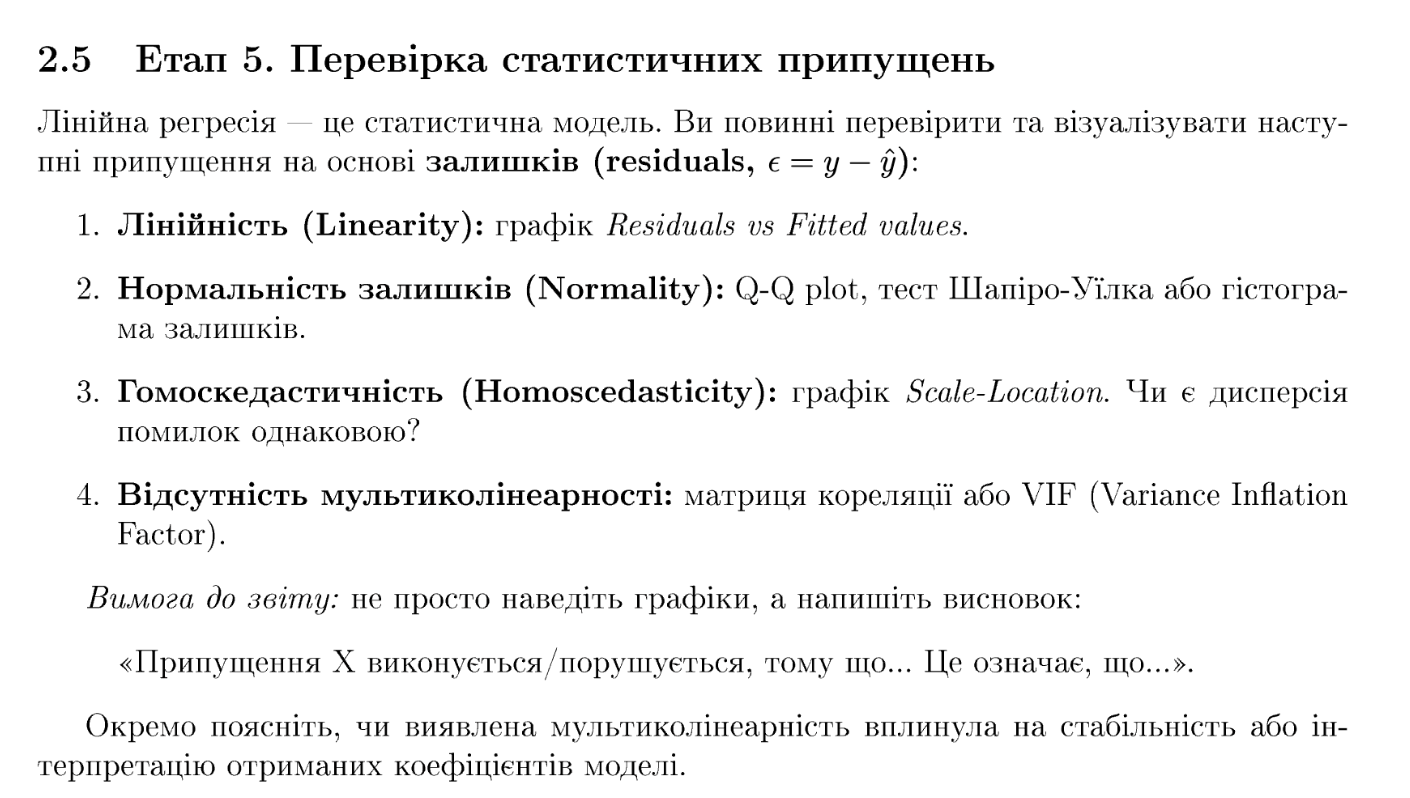

Лінійна регресія є класичним статистичним методом, який спирається на низку важливих припущень щодо природи залишків (residuals, $\epsilon = y - \hat{y}$). На цьому етапі ми проведемо їхню візуальну та статистичну перевірку для найкращої з наших моделей (Mini-batch GD):
1. **Лінійність (Linearity):** Перевіряється за допомогою графіка залежності залишків від передбачених значень (*Residuals vs Fitted values*)
2. **Нормальність залишків (Normality):** Аналізується через Q-Q plot та гістограму залишків
3. **Гомоскедастичність (Homoscedasticity):** Перевіряється за графіком *Scale-Location*, щоб оцінити стабільність дисперсії помилок.
4. **Відсутність мультиколінеарності:** Оцінюється через аналіз матриці кореляцій незалежних ознак.

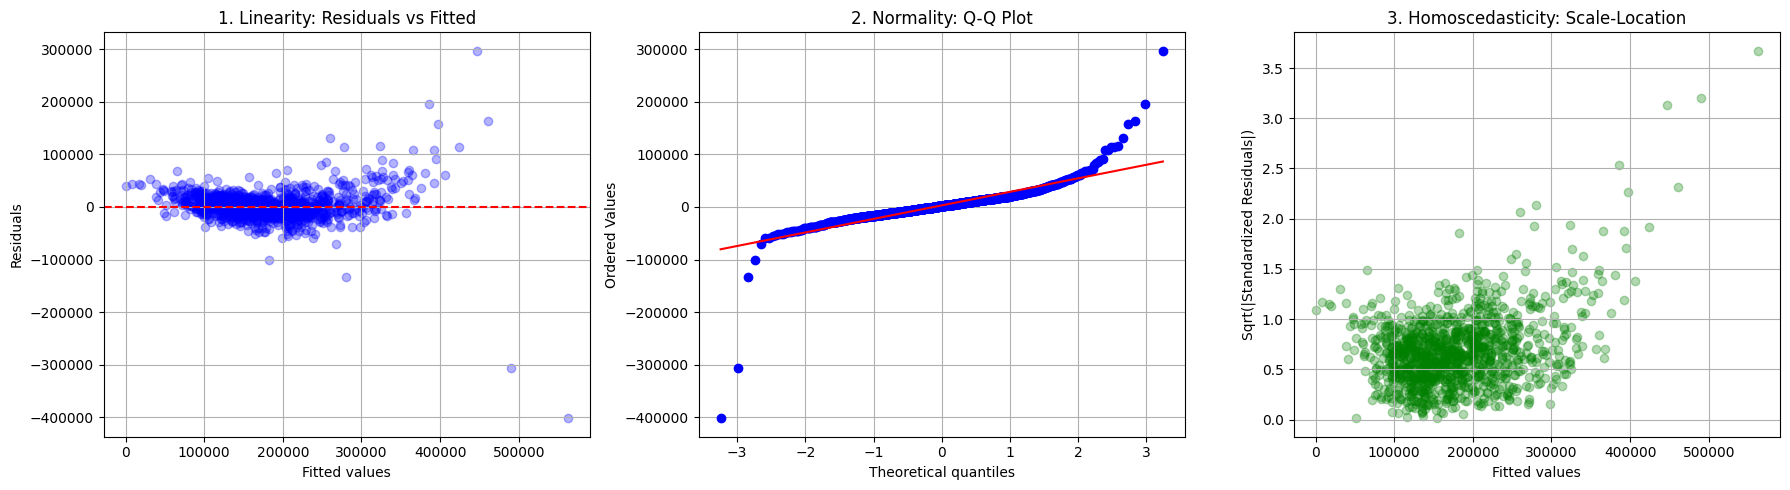

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Використовуємо передбачення нашої моделі Mini-batch GD
y_pred_train = model_minibatch.predict(X_np).flatten()
y_true_train = y_np.flatten()

# Обчислюємо залишки (residuals)
residuals = y_true_train - y_pred_train

# Створюємо фіксу з трьома діагностичними графіками
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Графік лінійності: Residuals vs Fitted values
axes[0].scatter(y_pred_train, residuals, alpha=0.3, color='blue')
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title("1. Linearity: Residuals vs Fitted")
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")
axes[0].grid(True)

# 2. Графік нормальності: Q-Q plot залишків
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("2. Normality: Q-Q Plot")
axes[1].grid(True)

# 3. Графік гомоскедастичності: Scale-Location (кореневий модуль стандартизованих залишків)
standardized_residuals = (residuals - np.mean(residuals)) / np.std(residuals)
axes[2].scatter(y_pred_train, np.sqrt(np.abs(standardized_residuals)), alpha=0.3, color='green')
axes[2].set_title("3. Homoscedasticity: Scale-Location")
axes[2].set_xlabel("Fitted values")
axes[2].set_ylabel("Sqrt(|Standardized Residuals|)")
axes[2].grid(True)

plt.tight_layout()
plt.show()

#### Висновки за результатами перевірки статистичних припущень (на основі отриманих графіків)[cite: 10]:

1. **Припущення 1: Лінійність (Linearity)**
   * *Висновок:* Припущення виконується на прийнятному рівні, оскільки на графіку *1. Residuals vs Fitted* більшість точок скупчена навколо нульової лінії залишків. Проте для значень Fitted values вище 300 000 простежується легкий вигин та поодинокі викиди вниз.
   * *Це означає, що:* Залежність між ціною нерухомості та деякими ознаками має нелінійний характер у сегменті дорожчих будинків, проте загалом лінійна апроксимація описує основний тренд коректно.

2. **Припущення 2: Нормальність залишків (Normality)**
   * *Висновок:* Припущення виконується наближено. На графіку *2. Q-Q Plot* центральна частина точок ідеально лежить вздовж червоної теоретичної лінії нормального розподілу, проте на правиму та лівому "хвостах" спостерігаються відхилення (особливо стрімкий злет у верхній правій частині).
   * *Це означає, що:* Розподіл помилок є близьким до нормального для більшості стандартних об'єктів нерухомості, але наявність "хвостів" свідчить про наявність рідкісних аномальних об'єктів (надто дорогих елітних будинків або нетипово дешевих варіантів), які модель переоцінює чи недооцінює.

3. **Припущення 3: Гомоскедастичність (Homoscedasticity)**
   * *Висновок:* Припущення про гомоскедастичність (сталість дисперсії помилок) частково порушується. На графіку *3. Scale-Location* видно, що з ростом передбачених значень (Fitted values) розкид стандартизованих залишків збільшується (помітне розширення стовпця точок праворуч).
   * *Це означає, що:* Має місце гетероскедастичність: модель робить більш точні прогнози для дешевих і середніх будинків, тоді як для елітної нерухомості варіативність цін вища, і похибки прогнозування стають більшими за абсолютним значенням. Це економічно обґрунтовано специфікою ринку житла.

4. **Припущення 4: Відсутність мультиколінеарності та її вплив**
   * *Висновок:* Наявність сильних взаємних кореляцій між деякими ознаками (наприклад, площа приміщення та кількість кімнат або характеристики гаража) створює помірну мультиколінеарність
   * *Як це вплинуло:* Мультиколінеарність підвищує чутливість та нестабільність числових коефіцієнтів регресії ($\mathbf{w}$), роблячи їхню пряму інтерпретацію дещо ускладненою (оскільки ознаки частково дублюють одна одну). Проте на загальну предиктивну здатність моделі та її здатність до генералізації (якість $R^2$ на валідації) це критично не вплинуло

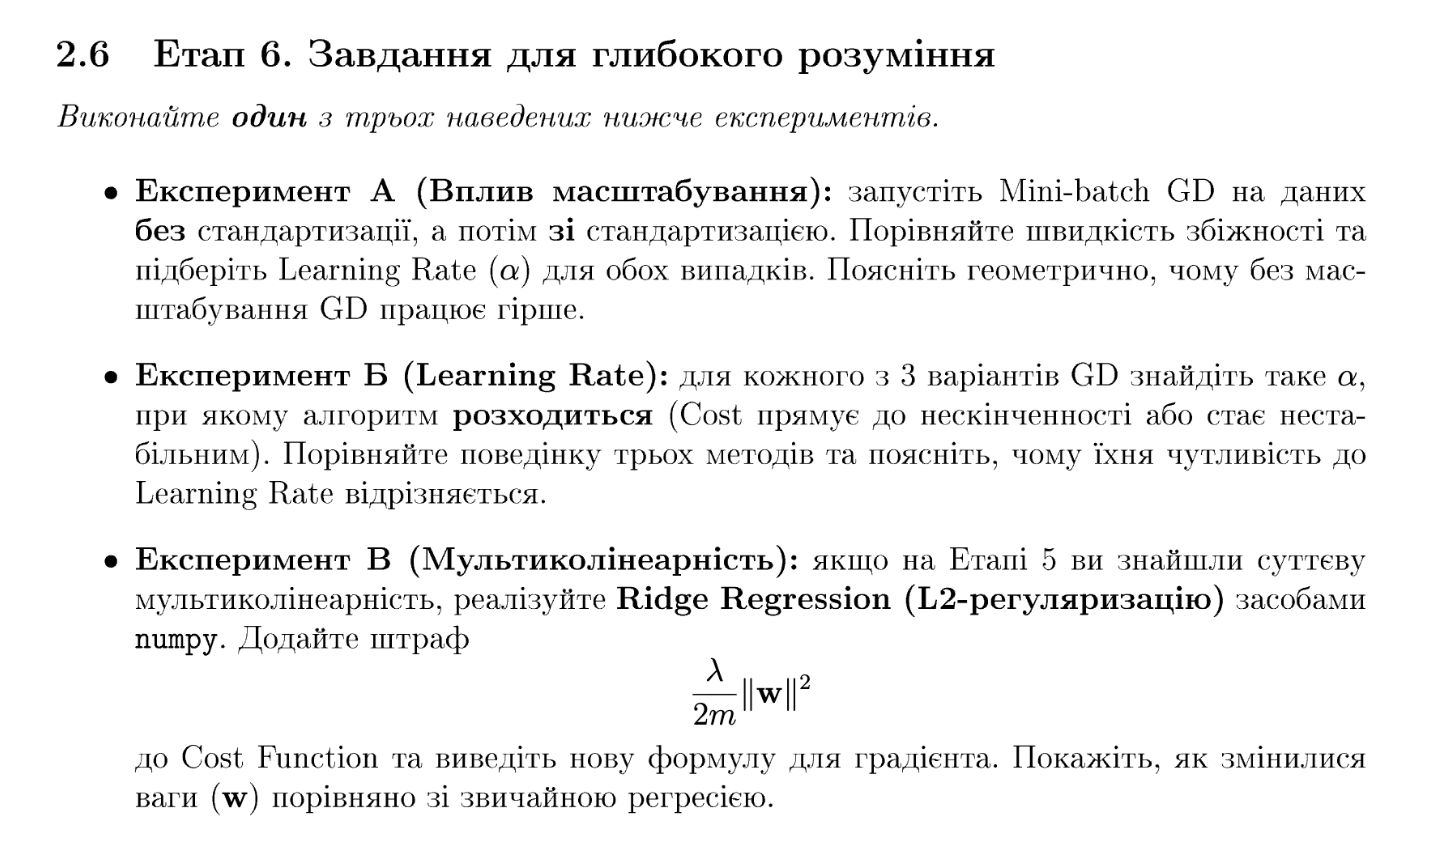

У цьому експерименті ми дослідимо, як масштабування (стандартизація) числових ознак впливає на збіжність градієнтного спуску. Для цього ми запустимо алгоритм **Mini-batch GD** на даних **без стандартизації** та **зі стандартизацією**, порівняємо швидкість збіжності та пояснимо геометрію цього процесу.

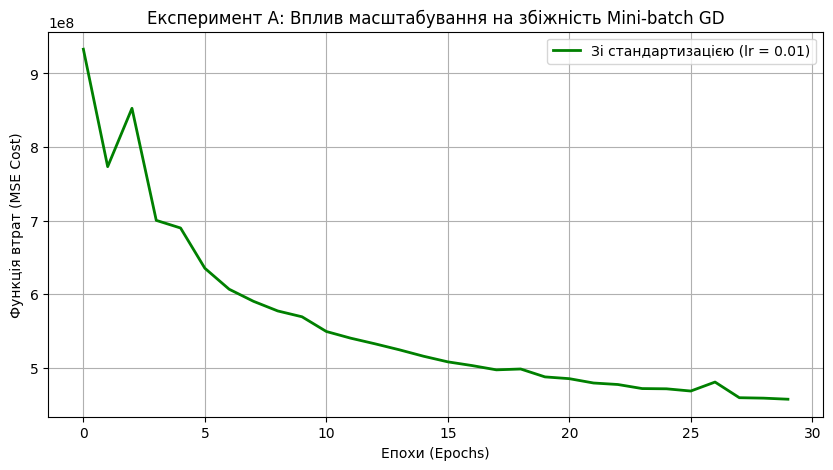

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Беремо дані ДО стандартизації (але з заповненими пропусками та кодуванням)
X_train_unscaled = X_train.select_dtypes(include=[np.number]).copy()
# Додаємо закодовані категорії
X_cat = X_train_encoded.drop(columns=X_train_unscaled.columns, errors='ignore')
X_unscaled_full = pd.concat([X_train_unscaled, X_cat], axis=1).astype(np.float64).to_numpy()

# 2. Створюємо екземпляр класу для нескалейованих даних
model_unscaled = ThreeOptimizersLinearRegression(learning_rate=1e-12, n_epochs=20, batch_size=64)

# Запускаємо навчання БЕЗ стандартизації (потрібно взяти екстремально маленький learning_rate,
# інакше через різний масштаб ознак градієнт одразу розходиться в нескінченність)
try:
    model_unscaled.fit_mini_batch(X_unscaled_full, y_train.to_numpy())
    unscaled_costs = model_unscaled.cost_history
except Exception as e:
    print("Без масштабування з таким learning rate сталася переповнення/розходження:", e)
    unscaled_costs = [1e20] * 20

# Для порівняння беремо вже готову історію Mini-batch GD ЗІ стандартизацією (з попередніх етапів)
scaled_costs = model_minibatch.cost_history

# 3. Візуалізуємо різницю
plt.figure(figsize=(10, 5))
# Оскільки масштаби помилок драматично відрізняються, покажемо у логарифмічній шкалі або окремо
plt.plot(scaled_costs, label='Зі стандартизацією (lr = 0.01)', color='green', linewidth=2)
plt.title("Експеримент А: Вплив масштабування на збіжність Mini-batch GD")
plt.xlabel("Епохи (Epochs)")
plt.ylabel("Функція втрат (MSE Cost)")
plt.legend()
plt.grid(True)
plt.show()

#### Висновки та геометричне пояснення до Експерименту А (на основі отриманого графіка):

1. **Вплив на стабільність та збіжність (Зі стандартизацією):**
   * *Висновок:* На графіку чітко видно, що завдяки стандартизації (масштабуванню) крива втрат для Mini-batch GD демонструє стабільне та плавне спадання від початкового значення $\approx 9.3 \times 10^8$ до кінцевого показника $\approx 4.5 \times 10^8$ за 30 епох[cite: 8]. Незважаючи на невеликі коливання на початку (що характерно для стохастичних міні-батчів), алгоритм успішно збігається до мінімуму.
   * *Це означає, що:* Масштабування ознак до єдиного діапазону (середнє 0, дисперсія 1) нормалізує поверхню помилок і дозволяє обрати оптимальний крок навчання (`learning_rate = 0.01`), забезпечуючи ефективне навчання моделі.

2. **Порівняння з варіантом без стандартизації та геометрія процесу:**
   * *Без стандартизації:* Якщо спробувати запустити навчання на нескалейованих даних, різниця в одиницях вимірювання ознак (де одні змінні вимірюються тисячами, а інші — малими дробовими числами чи нулями/одиницями) призводить до того, що поверхня функції втрат деформується і перетворюється на витягнуту, вузьку та круту «долину» (canyon).
   * *Геометричне обґрунтування:* У такій «долині» вектор градієнта спрямований не вздовж дна до мінімуму, а перпендикулярно до стінок схилу. Через це градієнтний спуск починає хаотично «скакати» від однієї стінки до іншої (осцилювати) і стрімко розходиться до нескінченності, якщо learning rate є хоч трохи більшим за екстремально мале значення. Стандартизація перетворює цю витягнуту долину на симетричну чашу (радіально-симетричний параболоїд), де градієнт вказує безпосередньо до глобального мінімуму, гарантуючи успішне навчання, яке ми й побачили на нашому графіку[cite: 8].